# log_engine : rapport du projet final Python ING3

## 1. Présentation

`log_engine` est un outil en ligne de commande qui lit de gros fichiers de logs sans les charger en mémoire, les nettoie, les analyse et sort un rapport de sécurité.

```text
main.py                 point d'entrée, lance tout le pipeline
log_engine/config.py    constantes (seuils, niveaux, format de ligne)
log_engine/models.py    types : ConnectionMeta (tuple), LogRecord (dictionnaire)
log_engine/ingestion.py Module 1 : générateurs et parsing
log_engine/pipeline.py  Module 2 : filter, map, match-case
log_engine/aggregation.py Module 3 : set, defaultdict, force brute
log_engine/rules.py     Module 4 : règles et apply_security_rules
log_engine/audit.py     Module 4 : globals() et locals()
log_engine/report.py    affichage et export du rapport
scripts/generate_logs.py création des logs de test
tests/                  tests pytest
```

Ce notebook ne contient aucun code métier : il importe `log_engine` et l'utilise.

In [1]:
import json
import os
import subprocess
import sys
import tracemalloc
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt

# Le notebook tourne dans notebooks/ : on se place à la racine du projet
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

from log_engine.aggregation import aggregate, compare_ips, detect_brute_force, load_blacklist
from log_engine.audit import audit_scope
from log_engine.config import ALLOWED_PORTS, NIGHT_END_HOUR
from log_engine.ingestion import parse_line, parse_stream, read_log_file, read_many_files
from log_engine.models import ConnectionMeta
from log_engine.pipeline import build_pipeline, categorize, normalize, route
from log_engine.rules import RULES, apply_security_rules

FILES = ["data/app_logs_1.log", "data/app_logs_2.log"]
blacklist = load_blacklist("data/blacklist.txt")
Path("output").mkdir(exist_ok=True)

## 2. Installation

Le projet tourne dans un environnement virtuel. Les paquets sont listés dans `requirements.txt`, généré avec `pip freeze`. Le cœur du projet n'utilise que la bibliothèque standard : les paquets externes servent aux tests, au style et aux graphiques.

```bash
python -m venv venv
venv\Scripts\activate        # Linux et macOS : source venv/bin/activate
pip install -r requirements.txt
```

## 3. Module 1 : générateurs et mémoire

`read_log_file` utilise `yield` : une seule ligne existe en mémoire à la fois. `read_many_files` enchaîne les fichiers avec `yield from`.

Un générateur pèse quelques centaines d'octets, quelle que soit la taille du fichier. La liste des mêmes lignes pèse beaucoup plus, et `sys.getsizeof` ne compte même pas le texte des lignes, seulement leurs références.

In [2]:
generator = read_log_file(FILES[0])
all_lines = list(read_log_file(FILES[0]))
print("Générateur :", sys.getsizeof(generator), "octets")
print("Liste de", len(all_lines), "lignes :", sys.getsizeof(all_lines), "octets, sans compter le texte")

Générateur : 232 octets
Liste de 1013 lignes : 8856 octets, sans compter le texte


On mesure ensuite le pic mémoire de la lecture et du parsing, avec un fichier 20 fois plus gros.

In [3]:
def measure_reading(path):
    tracemalloc.start()
    count = 0
    for record in parse_stream(read_log_file(path)):
        count = count + 1
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return count, peak


for lines in (1000, 20000):
    path = f"output/mesure_{lines}.log"
    subprocess.run([sys.executable, "scripts/generate_logs.py", path, "--lines", str(lines)], check=True)
    count, peak = measure_reading(path)
    size = Path(path).stat().st_size
    print(f"{count} lignes, {size // 1024} Ko sur le disque, pic {peak // 1024} Ko")

1013 lignes, 95 Ko sur le disque, pic 34 Ko


20013 lignes, 1883 Ko sur le disque, pic 42 Ko


Le pic de lecture ne dépend pas de la taille du fichier : c'est tout l'intérêt des générateurs.

Le pipeline complet garde en plus l'historique des connexions par IP (`login_events`), qui grossit lentement. Résultats mesurés avec `main.py` :

| Lignes de bruit | Taille | Pic mémoire | Durée |
| --- | --- | --- | --- |
| 20 000 | 2 Mo | 138 Ko | 5 s |
| 200 000 | 19 Mo | 707 Ko | 30 s |
| 1 000 000 | 96 Mo | 3 281 Ko | 100 s |

Sur 96 Mo de logs, le pic mémoire est 30 fois plus petit que le fichier. Il grossit avec le nombre de connexions, pas avec le texte lu. Les durées incluent le ralentissement dû à `tracemalloc`, sur un processeur à 2 cœurs.

## 4. Module 2 : pipeline fonctionnel

Une ligne avant et après `normalize` et `categorize`. Le niveau en minuscules et l'utilisateur en majuscules sont corrigés.

In [4]:
line = "2026-11-04T10:15:32 | error | 192.168.1.12:22/SSH | user=U042 | Disque lent"
record = parse_line(line)
print("Avant :", record["level"], record["user"])
record = categorize(normalize(record))
print("Après :", record["level"], record["user"])
print("Résumé :", record["summary"])
print("Catégorie :", record["category"])

Avant : error U042
Après : ERROR u042
Résumé : [ERROR] 192.168.1.12:22/SSH u042
Catégorie : raw


`route` remplace les `if / elif / else` par un `match-case`. Python teste les cas de haut en bas : `error` doit passer avant `event`, car un échec de connexion contient les deux clés.

In [5]:
examples = [
    "Session ouverte",
    {"event": "login_failed", "level": "ERROR", "code": 401},
    {"event": "login_success", "level": "INFO"},
    ConnectionMeta("1.2.3.4", 22, "SSH"),
    ConnectionMeta("1.2.3.4", 21, "FTP"),
    {"a": 1},
]
for item in examples:
    print(f"{route(item):<11} <- {item}")

raw         <- Session ouverte
error       <- {'event': 'login_failed', 'level': 'ERROR', 'code': 401}
event       <- {'event': 'login_success', 'level': 'INFO'}
connection  <- ConnectionMeta(ip='1.2.3.4', port=22, protocol='SSH')
unknown     <- ConnectionMeta(ip='1.2.3.4', port=21, protocol='FTP')
unknown     <- {'a': 1}


`build_pipeline` enchaîne les étapes sans créer de liste. Un générateur ne se lit qu'une fois : une fois parcouru, il est vide.

## 5. Module 3 : agrégation et force brute

`aggregate` remplit tous les compteurs en un seul passage.

In [6]:
stats = defaultdict(int)
agg = aggregate(build_pipeline(FILES, stats))
print("Lignes lues :", stats["read"], "| valides :", agg["total"])
print("Par niveau :", dict(agg["by_level"]))
print("Par catégorie :", dict(agg["by_category"]))
print("IP uniques en erreur :", len(agg["error_ips"]))

Lignes lues : 2024 | valides : 1888
Par niveau : {'ERROR': 607, 'WARNING': 176, 'INFO': 1049, 'CRITICAL': 56}
Par catégorie : {'error': 663, 'raw': 851, 'event': 374}
IP uniques en erreur : 44


Les 4 opérations d'ensembles entre les IP actives (`set`) et la liste noire (`frozenset`).

In [7]:
ip_sets = compare_ips(agg["active_ips"], blacklist)
print("Union, toutes les IP connues :", len(ip_sets["union"]))
print("Intersection, blacklistées encore actives :", sorted(ip_sets["blacklisted_active"]))
print("Différence, actives non blacklistées :", len(ip_sets["active_not_blacklisted"]))
print("Différence symétrique, d'un seul côté :", len(ip_sets["one_side_only"]))

Union, toutes les IP connues : 66
Intersection, blacklistées encore actives : ['192.168.1.17', '192.168.1.5', '203.0.113.10']
Différence, actives non blacklistées : 41
Différence symétrique, d'un seul côté : 63


`detect_brute_force` combine `for` (les IP), `while` (les tentatives), `continue` (IP sans risque), `break` (attaque trouvée) et le `else` de boucle (IP contrôlée jusqu'au bout, sans attaque).

Les logs contiennent 4 attaques cachées. `198.51.100.8` est un piège : 4 échecs puis une réussite, elle ne doit pas sortir au seuil 5.

In [8]:
for threshold in (5, 4, 9):
    result = detect_brute_force(agg["login_events"], threshold)
    print(f"Seuil {threshold} :", result["suspects"])

Seuil 5 : ['198.51.100.7', '203.0.113.10', '203.0.113.20']
Seuil 4 : ['192.168.1.14', '192.168.1.20', '192.168.1.33', '198.51.100.7', '198.51.100.8', '203.0.113.10', '203.0.113.20']
Seuil 9 : []


Au seuil 4, une IP du bruit peut sortir : 2 échecs à la fin du fichier 1, puis 2 au début du fichier 2. Le compteur continue d'un fichier à l'autre, c'est voulu.

## 6. Module 4 : moteur de règles et audit

`apply_security_rules(*args, **kwargs)` reçoit les règles dans `*args` et la configuration dans `**kwargs`. Le moteur ne change pas quand on change de règles. Le pipeline est reconstruit à chaque fois, car le précédent est vide.

In [9]:
def run_rules(names, sink):
    return apply_security_rules(
        *[RULES[name] for name in names],
        records=build_pipeline(FILES),
        audit_sink=sink,
        blacklist=blacklist,
        allowed_ports=ALLOWED_PORTS,
        night_end_hour=NIGHT_END_HOUR,
    )


audit = {}
print("2 règles :", dict(run_rules(["blacklist", "critical"], audit)["counts"]))
print("4 règles :", dict(run_rules(sorted(RULES), audit)["counts"]))

2 règles : {'rule_blacklisted_ip': 98, 'rule_critical_level': 56}
4 règles : {'rule_night_activity': 285, 'rule_blacklisted_ip': 98, 'rule_critical_level': 56, 'rule_suspicious_port': 16}


L'audit inspecte les variables de `locals()` dans le moteur, et de `globals()` dans `main.py`. Extrait des variables locales :

In [10]:
for variable in audit["apply_security_rules"]["variables"]:
    print(f"{variable['name']:<11}{variable['type']:<14}{variable['size_bytes']} octets")

args       tuple         72 octets
audit_sink dict          184 octets
counts     defaultdict   192 octets
kwargs     dict          184 octets
message    NoneType      16 octets
record     dict          272 octets
records    map           48 octets
rule       function      160 octets
samples    defaultdict   192 octets


## 7. Graphiques

Ils sont construits à partir de `output/rapport.json`, produit par la vraie commande.

In [11]:
command = [sys.executable, "main.py", *FILES, "--blacklist", "data/blacklist.txt", "--audit"]
result = subprocess.run(command, capture_output=True, encoding="utf-8", errors="replace")
print(result.stdout)
report = json.loads(Path("output/rapport.json").read_text(encoding="utf-8"))

================ RAPPORT DE SÉCURITÉ ================
Fichiers analysés : 2
Lignes lues : 2024 | valides : 1888 | rejetées : 136

Par niveau     INFO 1049 | WARNING 176 | ERROR 607 | CRITICAL 56
Par catégorie  raw 851 | error 663 | event 374

IP blacklistées encore actives (3) : 192.168.1.17, 192.168.1.5, 203.0.113.10
Force brute (seuil 5) : 3 IP suspectes
  - 198.51.100.7
  - 203.0.113.10
  - 203.0.113.20

Alertes par règle
  rule_blacklisted_ip     98
  rule_critical_level     56
  rule_night_activity    285
  rule_suspicious_port    16

Pic mémoire : 87 Ko
Rapport complet : output\rapport.json



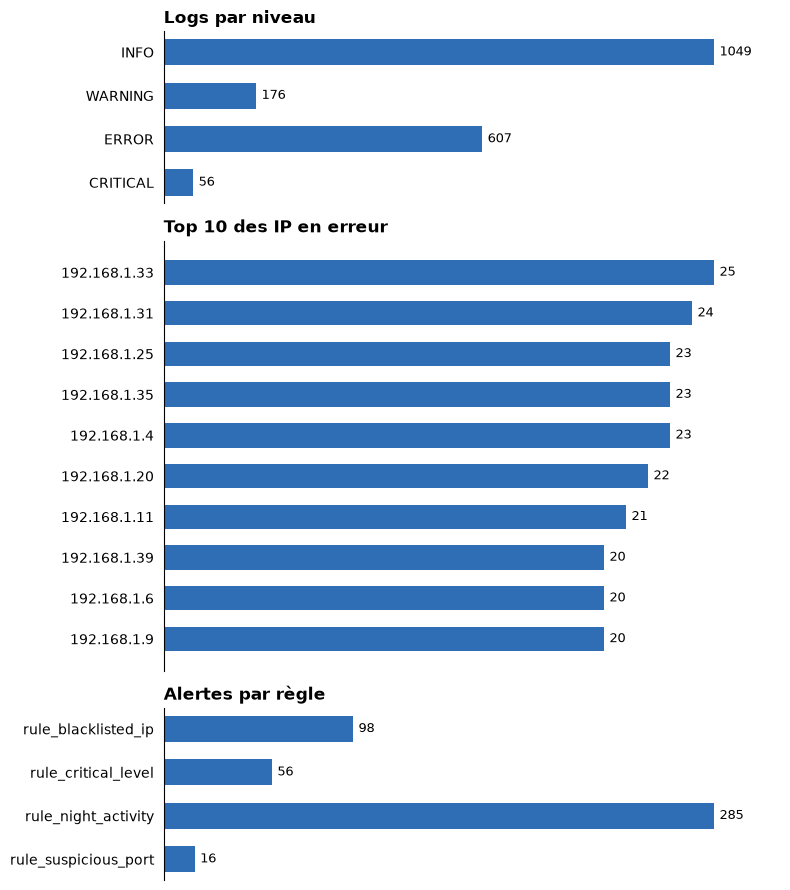

In [12]:
BAR_COLOR = "#2F6DB5"


def bar_chart(axis, title, labels, values):
    positions = range(len(labels))
    axis.barh(positions, values, color=BAR_COLOR, height=0.6)
    axis.set_yticks(positions, labels)
    axis.invert_yaxis()
    axis.set_title(title, loc="left", fontsize=12, fontweight="bold")
    axis.bar_label(axis.containers[0], padding=4, fontsize=9)
    axis.spines[["top", "right", "bottom"]].set_visible(False)
    axis.tick_params(left=False, bottom=False, labelbottom=False)
    axis.margins(x=0.12)


figure, axes = plt.subplots(3, 1, figsize=(8, 9), height_ratios=[4, 10, 4])
bar_chart(axes[0], "Logs par niveau", list(report["by_level"]), list(report["by_level"].values()))

top_ips = report["top_error_ips"]
ips = [pair[0] for pair in top_ips]
errors = [pair[1] for pair in top_ips]
bar_chart(axes[1], "Top 10 des IP en erreur", ips, errors)

counts = report["alerts"]["counts"]
bar_chart(axes[2], "Alertes par règle", list(counts), list(counts.values()))
figure.tight_layout()
plt.show()

## 8. Limites et pistes d'amélioration

- **Mémoire :** `login_events` garde une référence par tentative de connexion. La mémoire reste très faible mais grossit avec le nombre de connexions. Garder seulement la série en cours par IP la rendrait constante, sans la boucle `while` demandée.
- **Temps réel :** le projet lit des fichiers, et les relit deux fois (agrégation, puis règles). Un vrai flux réseau ne se relit pas : il faudrait faire les deux dans un seul passage.
- **Mesure mémoire :** `tracemalloc` ralentit beaucoup l'exécution. Elle sert pour la preuve, pas pour la production.
- **Validation des IP :** le format accepte `999.1.1`. Le module `ipaddress` serait plus strict.
- **Force brute :** les échecs comptent de suite sans regarder le temps écoulé entre eux.

## 9. Récapitulatif des fonctions

Pour chaque fonction : ce qu'elle reçoit, ce qu'elle fait, ce qu'elle rend.

| Fonction | Reçoit | Fait | Rend |
| --- | --- | --- | --- |
| `read_log_file` | un chemin | ouvre le fichier et le parcourt ligne par ligne avec `yield` | un générateur de lignes sans `\n` |
| `read_many_files` | des chemins | enchaîne les fichiers avec `yield from`, avertit si l'un manque | un générateur de lignes |
| `parse_payload` | le texte du payload | décode le JSON si le texte commence par `{` | un dictionnaire, le texte, ou `None` si le JSON est cassé |
| `parse_line` | une ligne | applique la regex, convertit la date, le port et le payload | un dictionnaire, ou `None` si la ligne est invalide |
| `parse_stream` | des lignes | appelle `parse_line` sur chacune | un générateur de dictionnaires et de `None` |
| `route` | un payload ou une connexion | teste les formats avec `match-case` | `raw`, `error`, `event`, `connection` ou `unknown` |
| `has_valid_connection` | un log | passe sa connexion à `route` | `True` si le protocole est connu |
| `normalize` | un log | met le niveau en majuscules, l'utilisateur en minuscules, ajoute `summary` | le même log |
| `categorize` | un log | passe son payload à `route` et ajoute `category` | le même log |
| `count_lines` | des lignes et un compteur | compte chaque ligne sans la stocker | un générateur de lignes |
| `build_pipeline` | des chemins, un compteur optionnel | enchaîne lecture, `filter` et `map` | un itérateur de logs propres |
| `load_blacklist` | un chemin | lit une IP par ligne, enlève les vides | un `frozenset` |
| `note_login` | l'historique, une IP, un payload | ajoute un `bool` si le log est une connexion | rien |
| `aggregate` | un flux de logs | remplit tous les compteurs en une seule boucle | un dictionnaire de compteurs et d'ensembles |
| `compare_ips` | les IP actives, la liste noire | applique `\|`, `&`, `-` et `^` | un dictionnaire de 4 ensembles |
| `detect_brute_force` | l'historique par IP, un seuil | cherche une série d'échecs assez longue | les listes triées `suspects` et `clean` |
| `rule_blacklisted_ip` | un log, des options | regarde si l'IP est dans la liste noire | un message ou `None` |
| `rule_critical_level` | un log, des options | regarde si le niveau est `CRITICAL` | un message ou `None` |
| `rule_suspicious_port` | un log, des options | regarde si le port est autorisé | un message ou `None` |
| `rule_night_activity` | un log, des options | regarde si l'heure est avant la fin de nuit | un message ou `None` |
| `apply_security_rules` | des règles et des options | applique chaque règle à chaque log, survit aux règles cassées | `counts` et `samples` |
| `audit_scope` | une portée, un nom | décrit les variables, sans les noms en `_` ni les modules | un dictionnaire d'audit |
| `save_audit` | l'audit, un chemin | écrit le JSON | rien |
| `sort_counts` | un compteur | trie du plus grand au plus petit | une liste de paires |
| `top_pairs` | un compteur | garde les 10 premières paires | une liste de listes pour le JSON |
| `build_report` | tous les résultats | convertit les `set` et assemble le rapport | un dictionnaire prêt pour le JSON |
| `join_counts` | un compteur | l'écrit sur une ligne | un texte |
| `print_summary`, `print_threats`, `print_alerts` | le rapport | affichent chacune une partie | rien |
| `print_report` | le rapport, son chemin | affiche tout le rapport | rien |
| `save_report` | le rapport, un chemin | écrit le JSON | rien |
| `positive_int` | le texte d'une option | le convertit et refuse ce qui est sous 1 | un entier |
| `build_parser` | rien | décrit les options de la commande | un `ArgumentParser` |
| `keep_existing` | des chemins | garde les fichiers présents, avertit pour les autres | une liste de chemins |
| `run_rules` | fichiers, noms de règles, liste noire, audit | lance le moteur sur un pipeline neuf | les alertes |
| `analyze` | fichiers, liste noire, options | enchaîne agrégation, détection, règles et audit | le rapport |
| `publish` | le rapport, son chemin | l'enregistre puis l'affiche | rien |
| `main` | rien | lit les options, vérifie les fichiers, lance tout | le code de sortie |